# 03 — 4DVarNet End-to-End on Lorenz-63

Demonstrates end-to-end training of `FourDVarNet1D` on simulated
Lorenz-63 windows, with train and validation learning curves.

In [1]:
# (NNX removed in Epic 0 — vardax is now equinox-native)
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import vardax
from vardax import Batch1D, FourDVarNet1D, simulate_lorenz63
from vardax._src.utils.masks import regular_mask
from vardax._src.utils.noise import add_gaussian_noise
from vardax._src.utils.patches import extract_patches, trajectory_to_xr_dataset
from vardax._src.utils.preprocessing import xr_to_batch1d
from vardax._src.utils.standardize import apply_standardization, compute_scaler_params

## Generate training data

Lorenz-63 windows from the simulator, split in time before patch
extraction (so no window straddles the train/validation boundary), masked
every other step, with Gaussian observation noise, and standardised with
the training statistics. The training windows are served as mini-batches.

In [2]:
key = jax.random.PRNGKey(0)
time_coords, states = simulate_lorenz63(
    key, sigma=10.0, rho=28.0, beta=8.0 / 3.0, dt=0.01, n_steps=5000, n_burn_in=1000
)
ds = trajectory_to_xr_dataset(states, time_coords, feature_names=["X", "Y", "Z"])
n_time = ds.sizes["time"]
ds_train = extract_patches(ds.isel(time=slice(0, int(0.8 * n_time))), n_patches=80, n_timesteps=20, seed=42)
ds_val = extract_patches(ds.isel(time=slice(int(0.8 * n_time), None)), n_patches=24, n_timesteps=20, seed=43)
ds_train = regular_mask(ds_train, variable="state", obs_interval=2)
ds_val = regular_mask(ds_val, variable="state", obs_interval=2)
ds_train = add_gaussian_noise(ds_train, variable="state", sigma=0.5, seed=0, name="obs")
ds_val = add_gaussian_noise(ds_val, variable="state", sigma=0.5, seed=1, name="obs")
mean, std = compute_scaler_params(ds_train, variable="state", mask_variable="mask")
ds_train = apply_standardization(ds_train, variables=["state", "obs"], mean=mean, std=std)
ds_val = apply_standardization(ds_val, variables=["state", "obs"], mean=mean, std=std)

batch_train = xr_to_batch1d(ds_train, state_var="state", obs_var="obs", mask_var="mask")
batch_val = xr_to_batch1d(ds_val, state_var="state", obs_var="obs", mask_var="mask")


def minibatches(batch, size):
    n = batch.input.shape[0]
    return [
        Batch1D(input=batch.input[i : i + size], mask=batch.mask[i : i + size], target=batch.target[i : i + size])
        for i in range(0, n, size)
    ]


train_batches = minibatches(batch_train, 8)
val_batches = minibatches(batch_val, 8)
print(f"train: {len(train_batches)} batches of {train_batches[0].input.shape}, val: {len(val_batches)} batches")

train: 10 batches of (8, 20, 3), val: 3 batches


## Define and train model

In [3]:
model = FourDVarNet1D(
    state_dim=3,
    n_time=20,
    latent_dim=8,
    hidden_dim=16,
    n_solver_steps=5,
    key=jax.random.PRNGKey(1),
)

model, train_losses, val_losses = vardax.examples.fit_demo(
    model,
    train_batches,
    lr=1e-3,
    n_epochs=10,
    val_batches=val_batches,
    verbose=True,
)

epoch 1/10 — train loss: 0.449124  val loss: 0.540365
epoch 2/10 — train loss: 0.340602  val loss: 0.414142
epoch 3/10 — train loss: 0.241983  val loss: 0.298865
epoch 4/10 — train loss: 0.167237  val loss: 0.217265
epoch 5/10 — train loss: 0.121264  val loss: 0.163330
epoch 6/10 — train loss: 0.089717  val loss: 0.122075
epoch 7/10 — train loss: 0.065446  val loss: 0.092940
epoch 8/10 — train loss: 0.048708  val loss: 0.072781
epoch 9/10 — train loss: 0.037982  val loss: 0.059519
epoch 10/10 — train loss: 0.030626  val loss: 0.049937


## Plot learning curves

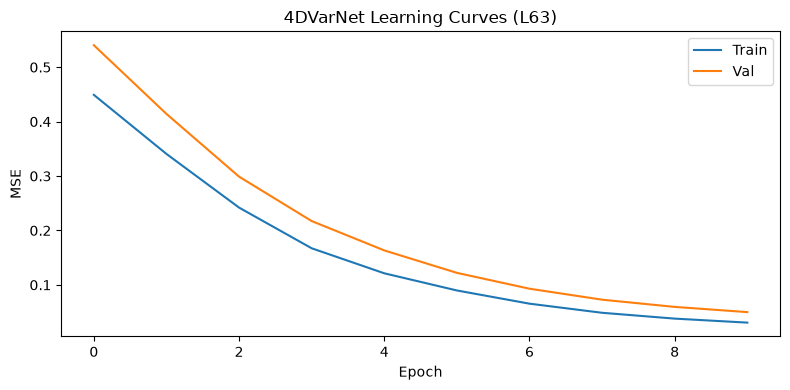

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(train_losses, label="Train")
ax.plot(val_losses, label="Val")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE")
ax.set_title("4DVarNet Learning Curves (L63)")
ax.legend()
plt.tight_layout()
plt.show()